In [1]:
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#Carregar o modelo
from keras.models import load_model
#salvar/carregar arquivos em diferentes formatos
import joblib
# Gerenciamento de arquivos e diretórios
import os

2026-10-18 10:14:14.927336: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 10:14:14.936787: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 10:14:15.133491: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 10:14:15.136641: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

In [2]:
diretorio = "./data/realcadas_verde_HUVEC/"
os.listdir(diretorio)[:4]

['imagens_HUVEC_validação_10%_fluore_2026-10-17.gz',
 'imagens_treino_fluore_HUVEC_100_75_50_25_2026-10-17.gz',
 'lista_imagem_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz',
 'lista_rotulos_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz']

In [3]:
#Importando o modelo contendo os valores previstos para o número de células nas imagens
modelo_maior_erro = load_model(f'{diretorio}modelo_fluore_HUVEC_100_75_50_25_2026-10-17.keras')
modelo_maior_erro

In [5]:
X_test_maior_erro = joblib.load(f'{diretorio}imagens_HUVEC_validação_10%_fluore_2026-10-17.gz') #carregando arquivo
X_test_maior_erro.shape

(30, 300, 300, 3)

In [7]:
y_test_maior_erro = joblib.load(f'{diretorio}rótulos_HUVEC_validação_10%_fluore_2026-10-17.gz') #carregando arquivo
y_test_maior_erro.shape

(30,)

In [8]:
#ROTULOS SALVOS EM LISTA

lista_observado_maior_erro = list(y_test_maior_erro)
len(lista_observado_maior_erro)

30

In [9]:
#PREDIÇÃO SALVO EM LISTA

dados_prev = modelo_maior_erro.predict(X_test_maior_erro)
lista_previsto_maior_erro = dados_prev.flatten().tolist()
len(lista_previsto_maior_erro)

1/1 [==============================] - 3s 3s/step


30

In [11]:
lista_previsto_maior_erro[:2]

[-3.7839908599853516, 5.22968053817749]

In [12]:
import pandas as pd
from scipy.stats.stats import pearsonr as stats

/tmp/ipykernel_3285/3864774765.py:2: DeprecationWarning: Please use `pearsonr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import pearsonr as stats


In [13]:
#DATAFRAME - ORGANIZAÇÃO DAS LISTAS
#COLUNA 1 ROTULO/ COLUNA 2 PREDITO

df_maior_erro = pd.DataFrame(zip(lista_observado_maior_erro,lista_previsto_maior_erro),
                             columns = ['Observed values','Lista preditos'])
df_maior_erro.head()

,Observed values,Lista preditos
0,0.071201,-3.783991
1,0.117536,5.229681
2,0.070178,-1.295777
3,0.067018,0.153003
4,0.068257,-2.482946


In [14]:
#ARREDONDANDO O PREDITO ('lista preditos')

teste = round(df_maior_erro['Lista preditos'],2)
df_maior_erro['Predicted values'] = teste
df_maior_erro.head()

,Observed values,Lista preditos,Predicted values
0,0.071201,-3.783991,-3.78
1,0.117536,5.229681,5.23
2,0.070178,-1.295777,-1.30
3,0.067018,0.153003,0.15
4,0.068257,-2.482946,-2.48


In [15]:
#REORGANIZANDO AS COLUNAS

df_maior_erro = df_maior_erro.reindex(columns=['Observed values','Predicted values','Lista preditos'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos
0,0.071201,-3.78,-3.783991
1,0.117536,5.23,5.229681
2,0.070178,-1.30,-1.295777
3,0.067018,0.15,0.153003
4,0.068257,-2.48,-2.482946


In [16]:
#BIBLIOTECA CORRELAÇÃO
from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação

/tmp/ipykernel_3285/923420305.py:2: DeprecationWarning: Please use `spearmanr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação


In [17]:
from scipy import stats

col1_obt = 0 #Observed value
col2_prev = 1 #Predicted values

# Verifique se as colunas contêm apenas valores numéricos
df_maior_erro[df_maior_erro.columns[col1_obt]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col1_obt]], errors='coerce')
df_maior_erro[df_maior_erro.columns[col2_prev]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col2_prev]], errors='coerce')

# Remova as linhas com valores NaN resultantes da conversão
df_maior_erro = df_maior_erro.dropna(subset=[df_maior_erro.columns[col1_obt], df_maior_erro.columns[col2_prev]])

# Calcular a correlação
pear_pos_maior_erro = stats.pearsonr(df_maior_erro[df_maior_erro.columns[col1_obt]],
                                     df_maior_erro[df_maior_erro.columns[col2_prev]])

print(pear_pos_maior_erro)

PearsonRResult(statistic=0.7555315280631332, pvalue=1.3891845195701299e-06)


<Figure size 1500x1500 with 0 Axes>

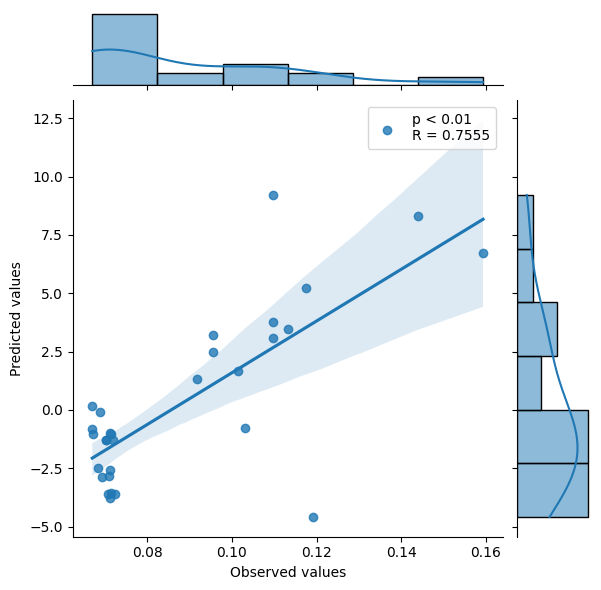

In [18]:
plt.figure(figsize=(15,15))
sns.jointplot(
    x=df_maior_erro.columns[col1_obt],
    y=df_maior_erro.columns[col2_prev],
    kind='reg',
    data=df_maior_erro#[df_maior_erro['Lista observado'] > 300]
)

if pear_pos_maior_erro[1] < 0.01:
  plt.legend(['p < ' + '0.01' + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e relse:
else:
  plt.legend(['p = ' + str(round(pear_pos_maior_erro[1],4)) + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e r

#Predição do modelo

In [19]:
predictions = modelo_maior_erro.predict(X_test_maior_erro)

1/1 [==============================] - 1s 661ms/step


In [20]:
# Compara as previsões com os valores reais
for i in range(len(predictions)):
    print(f"Valor real: {y_test_maior_erro[i]}, Valor predito: {predictions[i]}")

Valor real: 0.071201, Valor predito: [-3.7839909]
Valor real: 0.117536, Valor predito: [5.2296805]
Valor real: 0.070178, Valor predito: [-1.2957774]
Valor real: 0.067018, Valor predito: [0.1530027]
Valor real: 0.068257, Valor predito: [-2.482946]
Valor real: 0.101537, Valor predito: [1.6652285]
Valor real: 0.159318, Valor predito: [6.7328734]
Valor real: 0.095412, Valor predito: [2.504505]
Valor real: 0.091715, Valor predito: [1.317786]
Valor real: 0.071201, Valor predito: [-0.9735306]
Valor real: 0.113195, Valor predito: [3.4834998]
Valor real: 0.067253, Valor predito: [-1.0219105]
Valor real: 0.067018, Valor predito: [-0.8241232]
Valor real: 0.071546, Valor predito: [-3.5388691]
Valor real: 0.103083, Valor predito: [-0.7695101]
Valor real: 0.119242, Valor predito: [-4.577739]
Valor real: 0.068888, Valor predito: [-0.0756176]
Valor real: 0.070178, Valor predito: [-1.2957774]
Valor real: 0.071201, Valor predito: [-2.5525892]
Valor real: 0.072419, Valor predito: [-3.596947]
Valor real: 

#Predição de Frequência Absoluta

In [21]:
df_maior_erro[:2]

,Observed values,Predicted values,Lista preditos
0,0.071201,-3.78,-3.783991
1,0.117536,5.23,5.229681


In [22]:
df_maior_erro['Diferença'] = df_maior_erro['Observed values'] - df_maior_erro['Predicted values']

In [23]:
df_maior_erro[:3]

,Observed values,Predicted values,Lista preditos,Diferença
0,0.071201,-3.78,-3.783991,3.851201
1,0.117536,5.23,5.229681,-5.112464
2,0.070178,-1.30,-1.295777,1.370178


In [24]:
import matplotlib.pyplot as plt

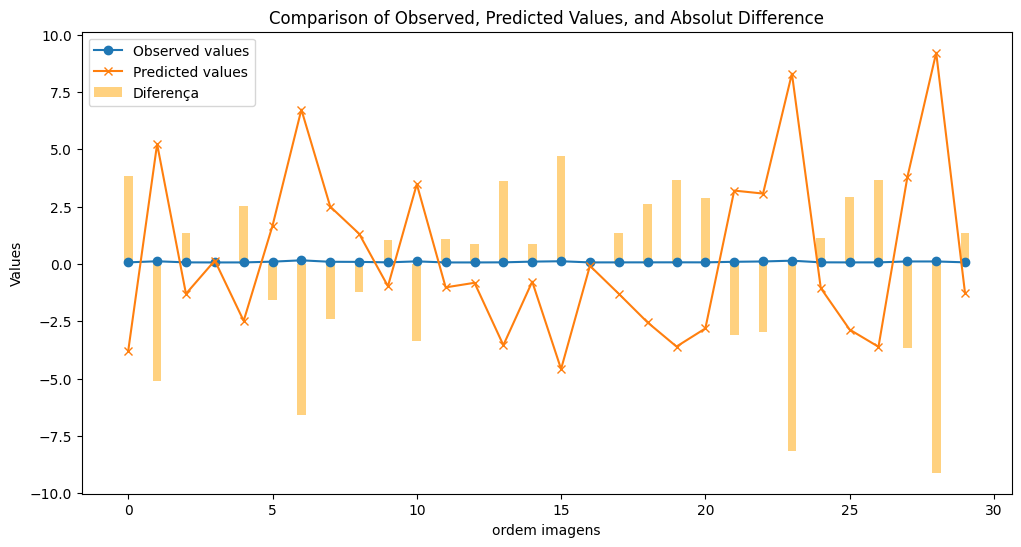

In [25]:
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença
plt.bar(df_maior_erro.index, df_maior_erro['Diferença'], width=0.3, alpha=0.5, label='Diferença', color='orange')

# Adiciona rótulos e título
plt.xlabel('ordem imagens')
plt.ylabel('Values')
plt.title('Comparison of Observed, Predicted Values, and Absolut Difference')
plt.legend()

# Mostra o gráfico
plt.show()

#Previsão Frequência Relativa (%)

In [27]:
df_maior_erro['Relative Difference (%)'] = ((df_maior_erro['Predicted values']*100) / df_maior_erro['Observed values'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos,Diferença,Relative Difference (%)
0,0.071201,-3.78,-3.783991,3.851201,-5308.914201
1,0.117536,5.23,5.229681,-5.112464,4449.700517
2,0.070178,-1.30,-1.295777,1.370178,-1852.432386
3,0.067018,0.15,0.153003,-0.082982,223.820466
4,0.068257,-2.48,-2.482946,2.548257,-3633.326985


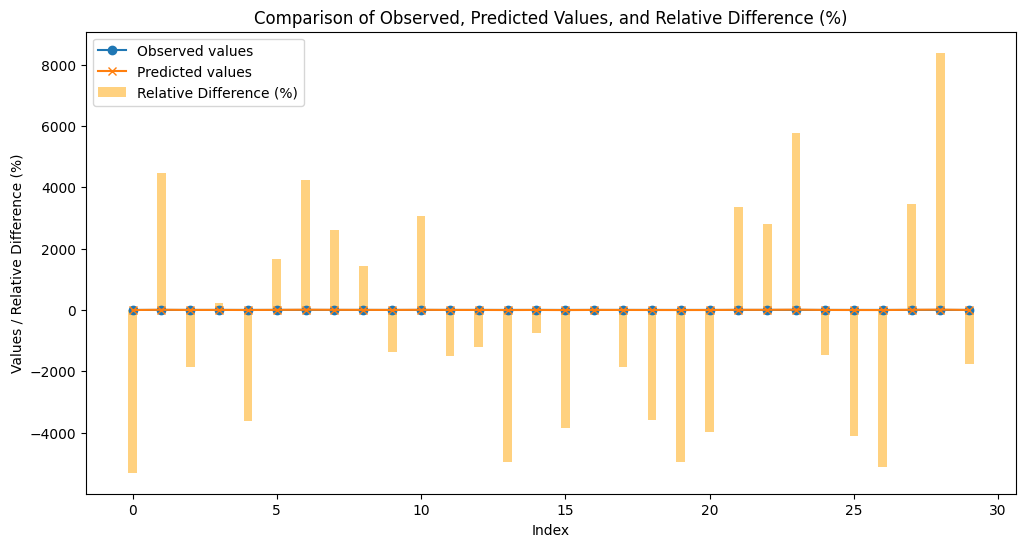

In [28]:
# Cria o gráfico comparando os valores
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença relativa
plt.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=0.3, alpha=0.5, label='Relative Difference (%)', color='orange')

# Adiciona rótulos e título
plt.xlabel('Index')
plt.ylabel('Values / Relative Difference (%)')
plt.title('Comparison of Observed, Predicted Values, and Relative Difference (%)')
plt.legend()

# Mostra o gráfico
plt.show()

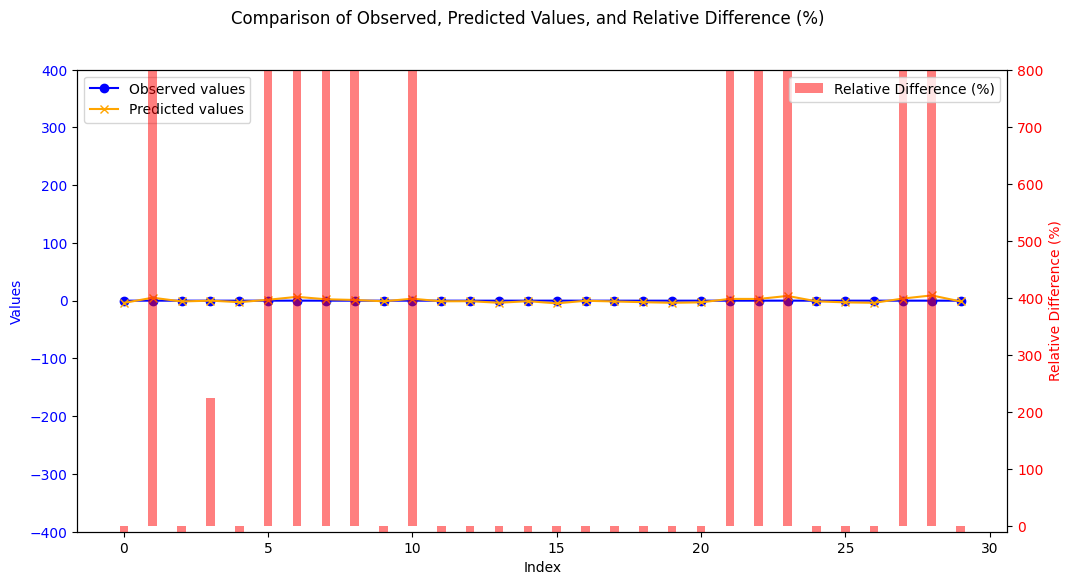

In [29]:
# Cria o gráfico com dois eixos Y
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo Y da esquerda (para valores observados e preditos)
ax1.set_xlabel('Index')
ax1.set_ylabel('Values', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x', color='orange')
ax1.tick_params(axis='y', labelcolor='blue')

# Mantém a escala normal do eixo Y da esquerda
# ax1.set_ylim(df_maior_erro[['Observed values', 'Predicted values']].min().min(),
#              df_maior_erro[['Observed values', 'Predicted values']].max().max())
ax1.set_ylim(-400, 400)

# Adiciona o segundo eixo Y à direita (para diferença relativa)
ax2 = ax1.twinx()
ax2.set_ylabel('Relative Difference (%)', color='red')


# Ajusta a largura das barras
bar_width = 0.3
ax2.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=bar_width, alpha=0.5, label='Relative Difference (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Corrige a amplitude do eixo Y da direita para -15 a 300
ax2.set_ylim(-10, 800)

# Títulos e legendas
fig.suptitle('Comparison of Observed, Predicted Values, and Relative Difference (%)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Mostra o gráfico
plt.show()